# Conda Environment: 11_PGLS

---

# Library Imports

In [1]:
%%capture

# For data management and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# For running R through Python
import rpy2.robjects as ro
from rpy2.robjects.packages import importr
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

# Load the rpy2 extension
%load_ext rpy2.ipython

# R libraries
importr('ape')
importr('nlme')
importr('qpcR')
importr('phytools')
importr('rr2');

---

# Create Output Directories

In [2]:
!mkdir -p ../Datasets/PGLS
!mkdir -p ../Figures/PGLS

---

# Phylogenetic Least Squares Modelling

## Prepare Tree and Trait Data

In [3]:
%%R

# Read in tree
tree = read.tree('../Datasets/Tree/Ultrametric_tree.nwk')

# Check tree
stopifnot(is.binary(tree))

# Get tree trip labels
tips = tree$tip.label

# Read in trait values
traits = read.csv('../Datasets/ASV_trait_data.csv', row.names= 1)

# Get indices of ASVs of interest
index_vector_traits = match(tips, rownames(traits))

# Select and reorder
traits = traits[index_vector_traits,]

In [4]:
%%R

# Z score normalisation of all variables
traits = data.frame(scale(traits))

In [5]:
# Pass to Python for plotting
traits = ro.r("traits")
with localconverter(ro.default_converter + pandas2ri.converter):
    traits = ro.conversion.rpy2py(traits)
    
# Export 
traits.to_csv("../Datasets/ASV_scaled_trait_data.csv")

---
## 
## 2-Week Fluctuation: Model Relationship Between Niche Breadth, Niche Position, and Fitness

### Fit model

In [6]:
%%R

traits$taxa = rownames(traits)

# Define correlation structures to test
bm_cor <- corBrownian(phy = tree, form= ~taxa)
lambda_cor <- corPagel(1, form= ~taxa, phy = tree, fixed = FALSE)
ou_cor <- corMartins(1, form= ~taxa, phy = tree, fixed = FALSE)
grafen_cor <- corGrafen(1, form= ~taxa, phy = tree, fixed = FALSE)

# Fit all models
## No phylogenetic signal
null_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML')

## Brownian motion correlation structure 
brownian_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= bm_cor)

## Pagel's Lambda correlation structure
lambda_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= lambda_cor)

## Ornstein-Uhlenbeck correlation structure
ou_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation = ou_cor)

## Grafen correlation structure
grafen_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= grafen_cor)

# Create data frame of model names and AICc values
model_names = c('null_model','brownian_model','lambda_model','ou_model','grafen_model')
                
aicc = c(AICc(null_model),AICc(brownian_model),AICc(lambda_model),AICc(ou_model),AICc(grafen_model))
model_weights = akaike.weights(aicc)$weights
model_fits = data.frame(Model= model_names, AICc= aicc, Akaike_weight= round(model_weights,2))
print(model_fits)

           Model     AICc Akaike_weight
1     null_model 1602.510          0.00
2 brownian_model 1649.718          0.00
3   lambda_model 1551.250          0.88
4       ou_model 1574.874          0.00
5   grafen_model 1555.175          0.12


In [7]:
%%R
lambda_model <- gls(TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'REML', correlation= lambda_cor)
summary(lambda_model)

Generalized least squares fit by REML
  Model: TwoWeeks_fitness ~ Bn + NP_TwoWeeks + Bn * NP_TwoWeeks 
  Data: traits 
       AIC      BIC    logLik
  1565.746 1591.757 -776.8731

Correlation Structure: corPagel
 Formula: ~taxa 
 Parameter estimate(s):
   lambda 
0.5758634 

Coefficients:
                     Value  Std.Error   t-value p-value
(Intercept)    -0.06345687 0.28704182 -0.221072  0.8251
Bn             -0.00174063 0.04521297 -0.038499  0.9693
NP_TwoWeeks    -0.12916558 0.04045887 -3.192516  0.0015
Bn:NP_TwoWeeks  0.05496938 0.03453478  1.591711  0.1120

 Correlation: 
               (Intr) Bn    NP_TwW
Bn             0.084              
NP_TwoWeeks    0.019  0.199       
Bn:NP_TwoWeeks 0.013  0.120 0.040 

Standardized residuals:
       Min         Q1        Med         Q3        Max 
-6.0754467 -0.4071918  0.1212809  0.4595542  3.3122069 

Residual standard error: 1.123432 
Degrees of freedom: 568 total; 564 residual


### Extract Pseudo-R2

In [8]:
%%R

R2_lik(lambda_model)

[1] 0.09574716


### Checking assumptions of homoskedasticity and phylogenetic signal in residuals


Phylogenetic signal lambda : 0.56862 
logL(lambda) : -769.589 



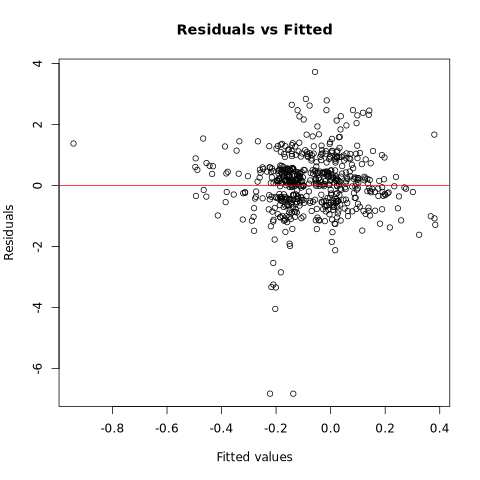

In [9]:
%%R
plot(fitted(lambda_model), residuals(lambda_model),
     xlab = "Fitted values", ylab = "Residuals", 
     main = "Residuals vs Fitted")
abline(h = 0, col = "red")

phylosig(tree, lambda_model$residuals, method = "lambda")

### Plotting

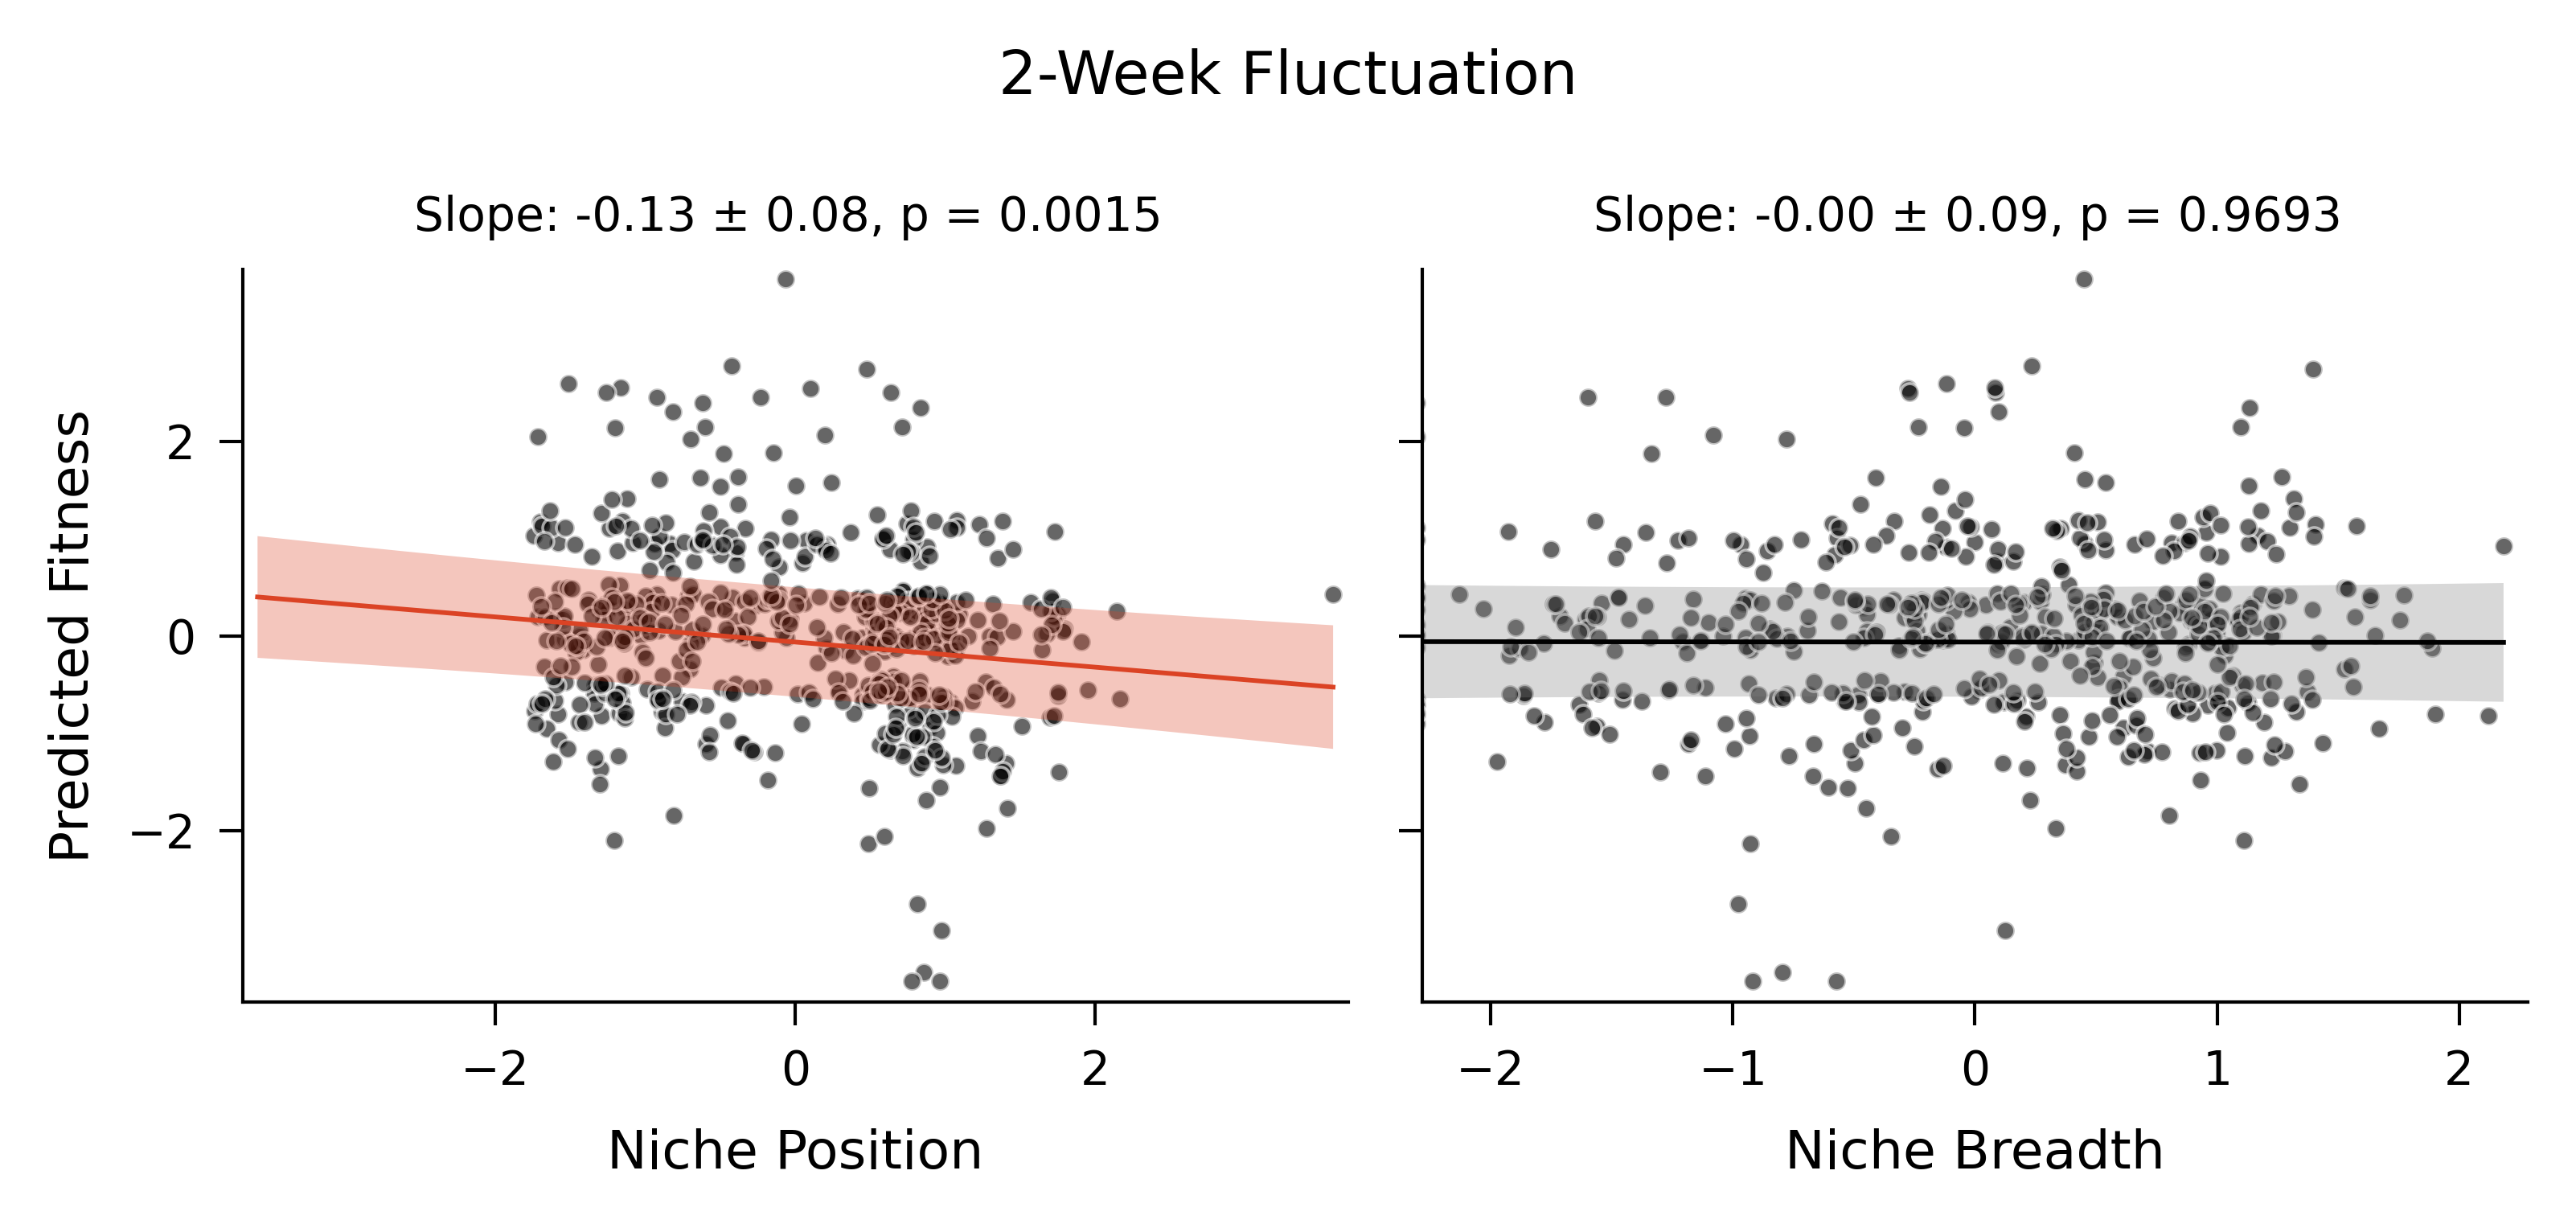

In [10]:
plt.style.use("../nature.mplstyle")

model = "lambda_model"
NP_trait = "NP_TwoWeeks"
fitness_trait = "TwoWeeks_fitness"
Condition = "2-Week Fluctuation"
ro.r(f"""
# Extract coefficients
beta = coef({model})
V = vcov({model})

# Build dataframe of trait values holding Bn at mean
simulated_np <- data.frame({NP_trait} = seq(-max(traits${NP_trait}),max(traits${NP_trait}),length.out= 200), Bn= mean(traits$Bn))

# Build dataframe of trait values holding NP at mean
simulated_Bn <- data.frame({NP_trait} = mean(traits${NP_trait}), Bn= seq(min(traits$Bn),max(traits$Bn),length.out= 200))

# Build design matrix for NP predictions
X_np = model.matrix(~ {NP_trait} * Bn, data= simulated_np)
X_np = X_np[,c(1,3,2,4)]

# Build design matrix for NP predictions
X_Bn = model.matrix(~ {NP_trait} * Bn, data= simulated_Bn)
X_Bn = X_Bn[,c(1,3,2,4)]

# Calculate fitted values and confidence intervals for NP
simulated_np$fit <- as.vector(X_np %*% beta) # fitting by matrix multiplication
SE_np <- sqrt(diag(X_np %*% V %*% t(X_np))) # Calculate SE for predicted values
simulated_np$lower <- simulated_np$fit - 1.96 * SE_np
simulated_np$upper <- simulated_np$fit + 1.96 * SE_np

# Calculate fitted values and confidence intervals for Bn
simulated_Bn$fit <- as.vector(X_Bn %*% beta) # fitting by matrix multiplication
SE_Bn <- sqrt(diag(X_Bn %*% V %*% t(X_Bn))) # Calculate SE for predicted values
simulated_Bn$lower <- simulated_Bn$fit - 1.96 * SE_Bn
simulated_Bn$upper <- simulated_Bn$fit + 1.96 * SE_Bn

# Extract coefficients and SE for model
coefficients = coef({model})
errors = summary({model})$tTable[, "Std.Error"]
pvalues = summary({model})$tTable[, "p-value"]

""")

# Pass to Python for plotting
simulated_np = ro.r("simulated_np")
simulated_Bn = ro.r("simulated_Bn")
coefficients = ro.r("coefficients")
errors = ro.r("errors")
pvalues = ro.r("pvalues")
with localconverter(ro.default_converter + pandas2ri.converter):
    simulated_np = ro.conversion.rpy2py(simulated_np)
    simulated_Bn = ro.conversion.rpy2py(simulated_Bn)
    coefficients = ro.conversion.rpy2py(coefficients)
    errors = ro.conversion.rpy2py(errors)
    pvalues = ro.conversion.rpy2py(pvalues)

# Make overall figure
fig,axes = plt.subplots(ncols= 2, nrows= 1, dpi= 600, figsize= (5.35,2.5), sharex= False, sharey= True)

# Niche position plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= NP_trait, y= fitness_trait, ax= axes[0], color= 'k', alpha= 0.6, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_np, x= NP_trait, y='fit', ax= axes[0], color= '#DB4325', linewidth= 0.7)
axes[0].fill_between(x = simulated_np[NP_trait], y1= simulated_np['lower'], y2= simulated_np['upper'],
                     alpha=0.3, color= '#DB4325', ec= None) # Confidence interval
## Add coefficient
axes[0].text(s= f"Slope: {coefficients[2]:.2f} ± {1.96 * errors[2]:.2f}, p = {pvalues[2]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[0].set_xlim((-max(traits[NP_trait])-0.1,max(traits[NP_trait])+0.1))
axes[0].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[0].set_xlabel('Niche Position', labelpad= 5)
axes[0].set_ylabel('Predicted Fitness')


# Niche breadth plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= 'Bn', y= fitness_trait, ax= axes[1], color= 'black', alpha= 0.6, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_Bn, x= 'Bn',y='fit', ax= axes[1], color= 'black', linewidth= 0.7)
axes[1].fill_between(x = simulated_Bn['Bn'], y1= simulated_Bn['lower'], y2= simulated_Bn['upper'],
                     alpha=0.3, color= 'grey', ec= None) # Confidence interval
## Add coefficient
axes[1].text(s= f"Slope: {coefficients[1]:.2f} ± {1.96 * errors[1]:.2f}, p = {pvalues[1]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[1].set_xlim((-max(traits['Bn'])-0.1,max(traits['Bn']+0.1)))
axes[1].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[1].set_xlabel('Niche Breadth', labelpad= 5)
axes[1].set_ylabel('')



# Global Tidy up
sns.despine()
fig.suptitle(Condition)
plt.tight_layout()

# Save
plt.savefig('../Figures/PGLS/TwoWeeks_PGLS.svg')
plt.savefig('../Figures/PGLS/TwoWeeks_PGLS.png')

---
## 1-Week Fluctuation: Model Relationship Between Niche Breadth, Niche Position, and Fitness

### Fit model

In [11]:
%%R

traits$taxa = rownames(traits)

# Define correlation structures to test
bm_cor <- corBrownian(phy = tree, form= ~taxa)
lambda_cor <- corPagel(1, form= ~taxa, phy = tree, fixed = FALSE)
ou_cor <- corMartins(1, form= ~taxa, phy = tree, fixed = FALSE)
grafen_cor <- corGrafen(1, form= ~taxa, phy = tree, fixed = FALSE)

# Fit all models
## No phylogenetic signal
null_model <- gls(OneWeek_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML')

## Brownian motion correlation structure 
brownian_model <- gls(OneWeek_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= bm_cor)

## Pagel's Lambda correlation structure
lambda_model <- gls(OneWeek_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= lambda_cor)

## Ornstein-Uhlenbeck correlation structure
ou_model <- gls(OneWeek_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation = ou_cor)

## Grafen correlation structure
grafen_model <- gls(OneWeek_fitness ~ Bn + NP_TwoWeeks + Bn*NP_TwoWeeks, data= traits, method= 'ML', correlation= grafen_cor)

# Create data frame of model names and AICc values
model_names = c('null_model','brownian_model','lambda_model','ou_model','grafen_model')
                
aicc = c(AICc(null_model),AICc(brownian_model),AICc(lambda_model),AICc(ou_model),AICc(grafen_model))
model_weights = akaike.weights(aicc)$weights
model_fits = data.frame(Model= model_names, AICc= aicc, Akaike_weight= round(model_weights,2))
print(model_fits)

           Model     AICc Akaike_weight
1     null_model 1608.186          0.00
2 brownian_model 1819.916          0.00
3   lambda_model 1602.037          0.08
4       ou_model 1607.327          0.01
5   grafen_model 1597.048          0.92


In [12]:
%%R
grafen_model <- gls(OneWeek_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'REML', correlation= grafen_cor)
summary(grafen_model)

Generalized least squares fit by REML
  Model: OneWeek_fitness ~ Bn + NP_fluctuation + Bn * NP_fluctuation 
  Data: traits 
       AIC      BIC    logLik
  1597.788 1623.798 -792.8938

Correlation Structure: corGrafen
 Formula: ~taxa 
 Parameter estimate(s):
       rho 
0.02319947 

Coefficients:
                        Value  Std.Error   t-value p-value
(Intercept)       -0.01980104 0.11286845 -0.175435  0.8608
Bn                 0.04032953 0.04460121  0.904225  0.3663
NP_fluctuation    -0.20148672 0.04231669 -4.761401  0.0000
Bn:NP_fluctuation  0.03817604 0.04027268  0.947939  0.3436

 Correlation: 
                  (Intr) Bn    NP_flc
Bn                0.077              
NP_fluctuation    0.024  0.108       
Bn:NP_fluctuation 0.005  0.122 0.122 

Standardized residuals:
        Min          Q1         Med          Q3         Max 
-3.09274249 -0.74149903 -0.06367089  0.48925950  3.33524994 

Residual standard error: 0.9898365 
Degrees of freedom: 568 total; 564 residual


### Extract Pseudo-R2

In [13]:
%%R

R2_lik(grafen_model)

[1] 0.04327119


### Checking assumptions of homoskedasticity and phylogenetic signal in residuals


Phylogenetic signal lambda : 0.140669 
logL(lambda) : -787.263 



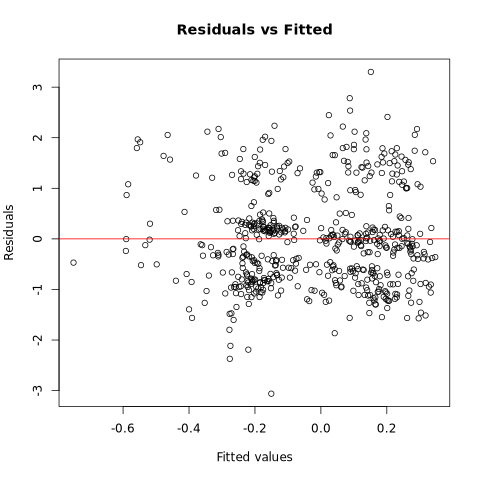

In [14]:
%%R
plot(fitted(grafen_model), residuals(grafen_model),
     xlab = "Fitted values", ylab = "Residuals", 
     main = "Residuals vs Fitted")
abline(h = 0, col = "red")

phylosig(tree, grafen_model$residuals, method = "lambda")

### Plotting

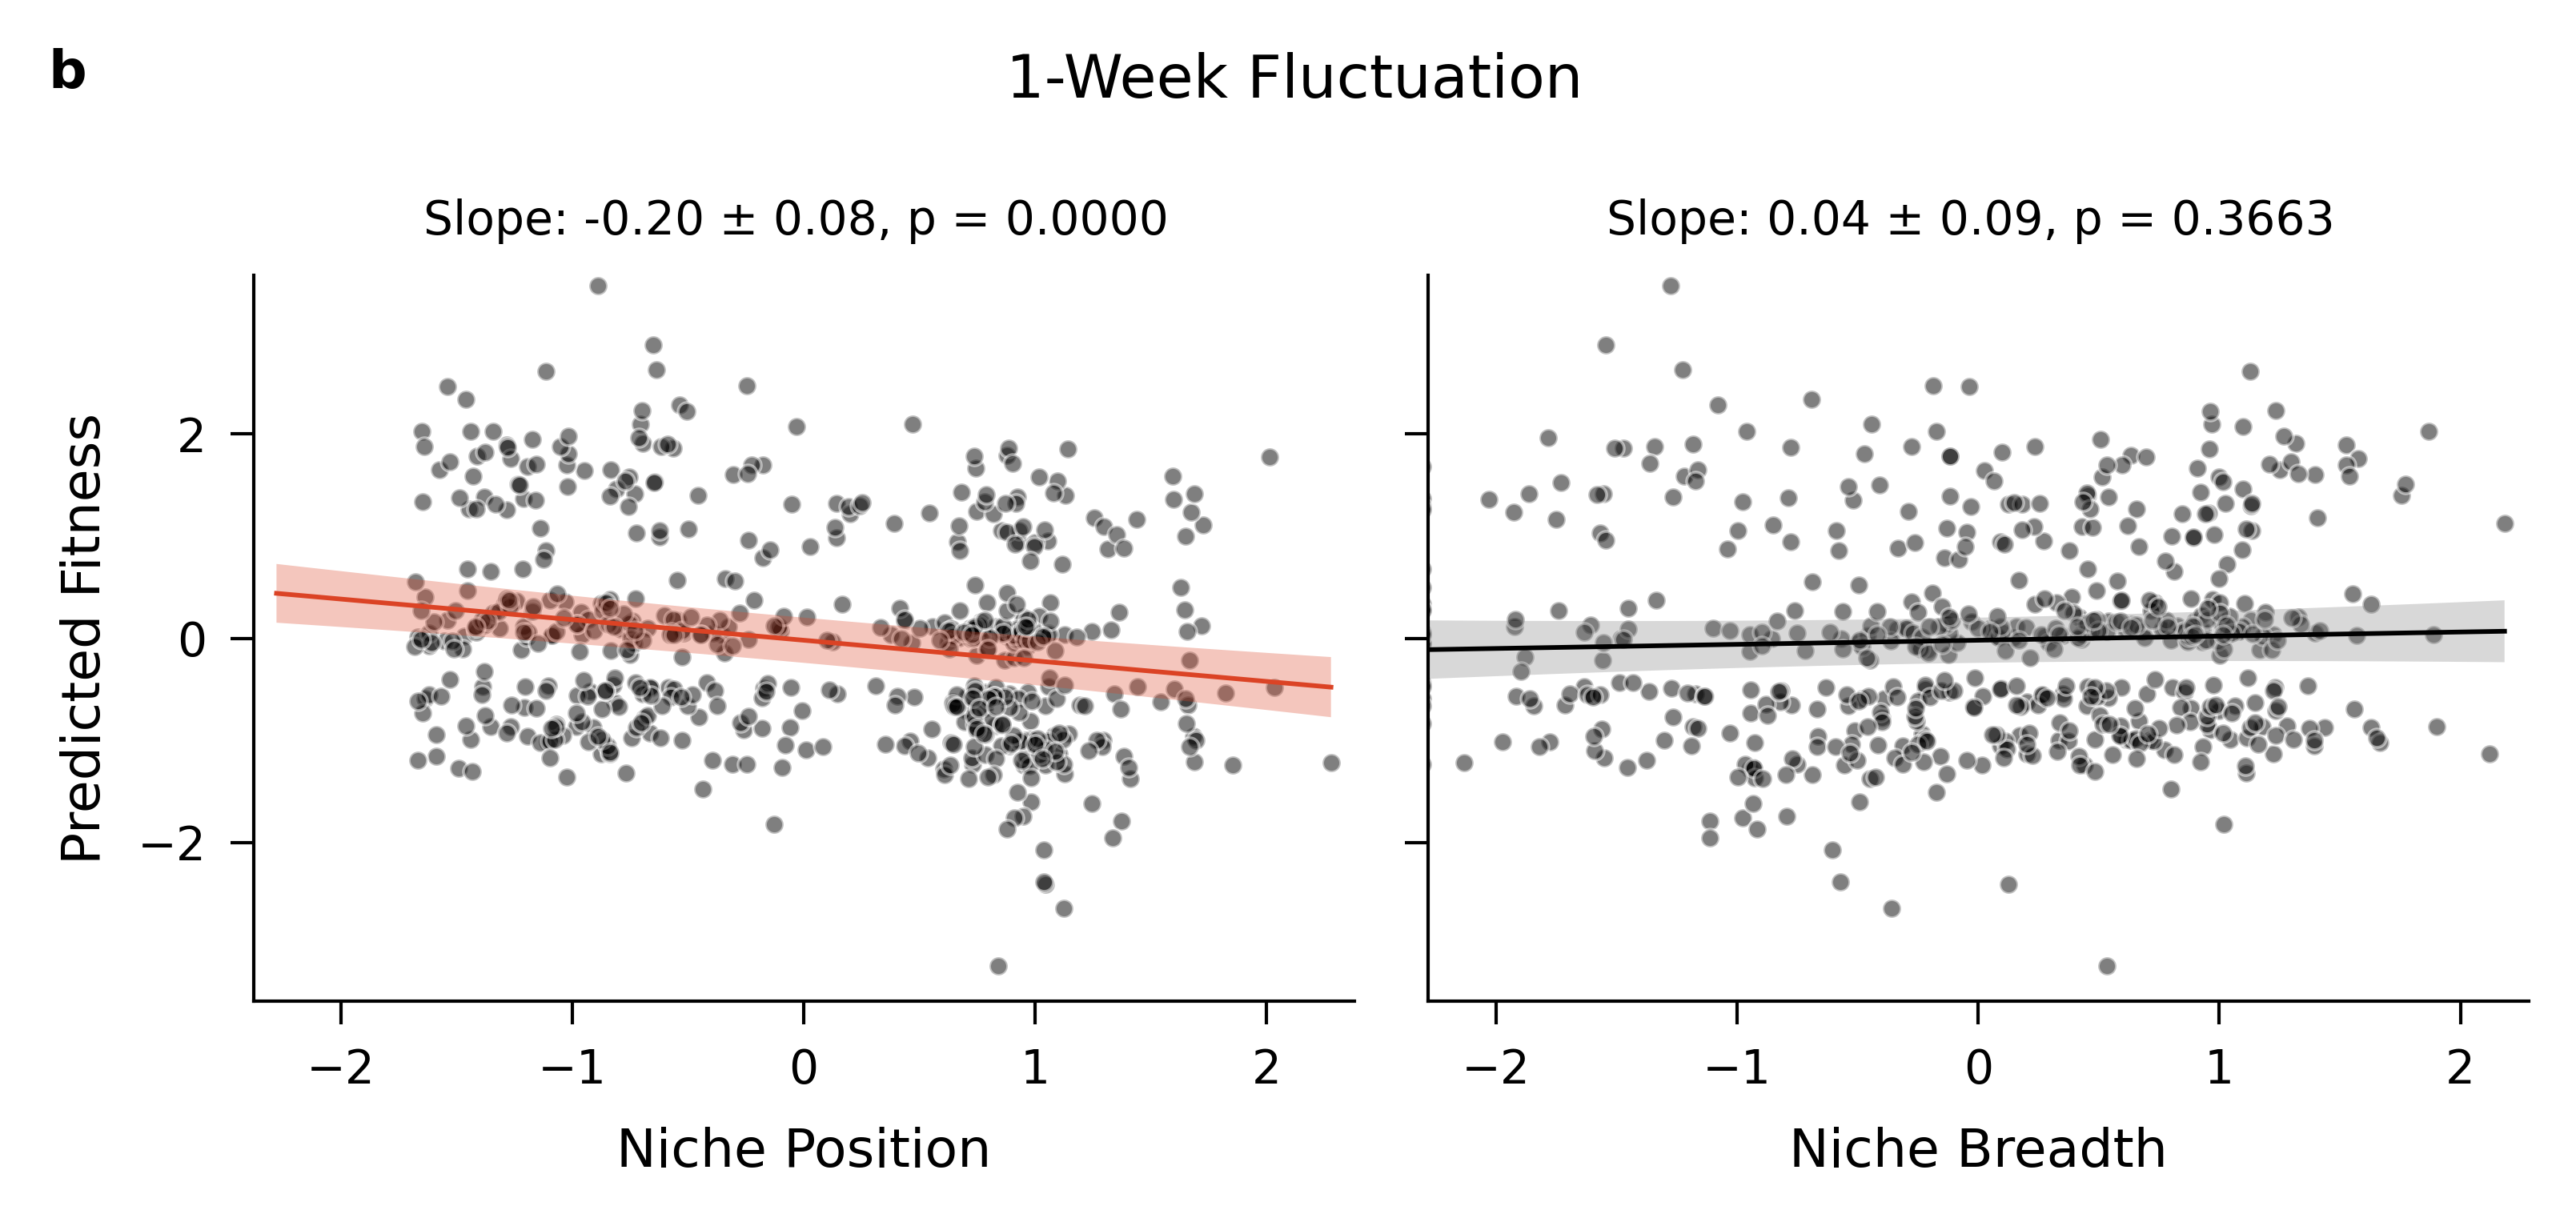

In [15]:
plt.style.use("../nature.mplstyle")

model = "grafen_model"
NP_trait = "NP_fluctuation"
fitness_trait = "OneWeek_fitness"
Condition = "1-Week Fluctuation"
ro.r(f"""
# Extract coefficients
beta = coef({model})
V = vcov({model})

# Build dataframe of trait values holding Bn at mean
simulated_np <- data.frame({NP_trait} = seq(-max(traits${NP_trait}),max(traits${NP_trait}),length.out= 200), Bn= mean(traits$Bn))

# Build dataframe of trait values holding NP at mean
simulated_Bn <- data.frame({NP_trait} = mean(traits${NP_trait}), Bn= seq(min(traits$Bn),max(traits$Bn),length.out= 200))

# Build design matrix for NP predictions
X_np = model.matrix(~ {NP_trait} * Bn, data= simulated_np)
X_np = X_np[,c(1,3,2,4)]

# Build design matrix for NP predictions
X_Bn = model.matrix(~ {NP_trait} * Bn, data= simulated_Bn)
X_Bn = X_Bn[,c(1,3,2,4)]

# Calculate fitted values and confidence intervals for NP
simulated_np$fit <- as.vector(X_np %*% beta) # fitting by matrix multiplication
SE_np <- sqrt(diag(X_np %*% V %*% t(X_np))) # Calculate SE for predicted values
simulated_np$lower <- simulated_np$fit - 1.96 * SE_np
simulated_np$upper <- simulated_np$fit + 1.96 * SE_np

# Calculate fitted values and confidence intervals for Bn
simulated_Bn$fit <- as.vector(X_Bn %*% beta) # fitting by matrix multiplication
SE_Bn <- sqrt(diag(X_Bn %*% V %*% t(X_Bn))) # Calculate SE for predicted values
simulated_Bn$lower <- simulated_Bn$fit - 1.96 * SE_Bn
simulated_Bn$upper <- simulated_Bn$fit + 1.96 * SE_Bn

# Extract coefficients and SE for model
coefficients = coef({model})
errors = summary({model})$tTable[, "Std.Error"]
pvalues = summary({model})$tTable[, "p-value"]

""")

# Pass to Python for plotting
simulated_np = ro.r("simulated_np")
simulated_Bn = ro.r("simulated_Bn")
coefficients = ro.r("coefficients")
errors = ro.r("errors")
pvalues = ro.r("pvalues")
with localconverter(ro.default_converter + pandas2ri.converter):
    simulated_np = ro.conversion.rpy2py(simulated_np)
    simulated_Bn = ro.conversion.rpy2py(simulated_Bn)
    coefficients = ro.conversion.rpy2py(coefficients)
    errors = ro.conversion.rpy2py(errors)
    pvalues = ro.conversion.rpy2py(pvalues)

# Make overall figure
fig,axes = plt.subplots(ncols= 2, nrows= 1, dpi= 600, figsize= (5.35,2.5), sharex= False, sharey= True)

# Niche position plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= NP_trait, y= fitness_trait, ax= axes[0], color= 'k', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_np, x= NP_trait, y='fit', ax= axes[0], color= '#DB4325', linewidth= 0.7)
axes[0].fill_between(x = simulated_np[NP_trait], y1= simulated_np['lower'], y2= simulated_np['upper'],
                     alpha=0.3, color= '#DB4325', ec= None) # Confidence interval
## Add coefficient
axes[0].text(s= f"Slope: {coefficients[2]:.2f} ± {1.96 * errors[2]:.2f}, p = {pvalues[2]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[0].set_xlim((-max(traits[NP_trait])-0.1,max(traits[NP_trait])+0.1))
axes[0].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[0].set_xlabel('Niche Position', labelpad= 5)
axes[0].set_ylabel('Predicted Fitness')


# Niche breadth plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= 'Bn', y= fitness_trait, ax= axes[1], color= 'black', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_Bn, x= 'Bn',y='fit', ax= axes[1], color= 'black', linewidth= 0.7)
axes[1].fill_between(x = simulated_Bn['Bn'], y1= simulated_Bn['lower'], y2= simulated_Bn['upper'],
                     alpha=0.3, color= 'grey', ec= None) # Confidence interval
## Add coefficient
axes[1].text(s= f"Slope: {coefficients[1]:.2f} ± {1.96 * errors[1]:.2f}, p = {pvalues[1]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[1].set_xlim((-max(traits['Bn'])-0.1,max(traits['Bn']+0.1)))
axes[1].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[1].set_xlabel('Niche Breadth', labelpad= 5)
axes[1].set_ylabel('')


# Global Tidy up
sns.despine()
fig.suptitle(Condition)
fig.text(x= 0.015, y= 0.95, s= 'b', weight= 'bold',fontsize= 8)
plt.tight_layout()

# Save
plt.savefig('../Figures/PGLS/OneWeek_PGLS.svg')
plt.savefig('../Figures/PGLS/OneWeek_PGLS.png')

---
## 2-Day Fluctuation: Model Relationship Between Niche Breadth, Niche Position, and Fitness

### Fit model

In [16]:
%%R

# Define correlation structures to test
bm_cor <- corBrownian(phy = tree, form= ~taxa)
lambda_cor <- corPagel(1, form= ~taxa, phy = tree, fixed = FALSE)
ou_cor <- corMartins(1, form= ~taxa, phy = tree, fixed = FALSE)
grafen_cor <- corGrafen(1, form= ~taxa, phy = tree, fixed = FALSE)

# Fit all models
## No phylogenetic signal
null_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'ML')

## Brownian motion correlation structure 
brownian_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'ML', correlation= bm_cor)

## Pagel's Lambda correlation structure
lambda_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'ML', correlation= lambda_cor)

## Ornstein-Uhlenbeck correlation structure
ou_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'ML', correlation = ou_cor)

## Grafen correlation structure
grafen_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'ML', correlation= grafen_cor)

# Create data frame of model names and AICc values
model_names = c('null_model','brownian_model','lambda_model','ou_model','grafen_model')
                
aicc = c(AICc(null_model),AICc(brownian_model),AICc(lambda_model),AICc(ou_model),AICc(grafen_model))
model_weights = akaike.weights(aicc)$weights
model_fits = data.frame(Model= model_names, AICc= aicc, Akaike_weight= round(model_weights,2))
print(model_fits)

           Model     AICc Akaike_weight
1     null_model 1542.643          0.23
2 brownian_model 1759.169          0.00
3   lambda_model 1543.497          0.15
4       ou_model 1543.192          0.17
5   grafen_model 1541.243          0.46


In [17]:
%%R
grafen_model <- gls(TwoDays_fitness ~ Bn + NP_fluctuation + Bn*NP_fluctuation, data= traits, method= 'REML', correlation= grafen_cor)
summary(grafen_model)

Generalized least squares fit by REML
  Model: TwoDays_fitness ~ Bn + NP_fluctuation + Bn * NP_fluctuation 
  Data: traits 
       AIC      BIC    logLik
  1558.224 1584.234 -773.1118

Correlation Structure: corGrafen
 Formula: ~taxa 
 Parameter estimate(s):
       rho 
0.01090933 

Coefficients:
                        Value  Std.Error   t-value p-value
(Intercept)       -0.00604334 0.08139385 -0.074248  0.9408
Bn                 0.20474831 0.04211011  4.862213  0.0000
NP_fluctuation    -0.28399490 0.04055977 -7.001886  0.0000
Bn:NP_fluctuation -0.00625065 0.03892234 -0.160593  0.8725

 Correlation: 
                  (Intr) Bn    NP_flc
Bn                0.070              
NP_fluctuation    0.018  0.093       
Bn:NP_fluctuation 0.012  0.126 0.125 

Standardized residuals:
       Min         Q1        Med         Q3        Max 
-3.5714938 -0.5723797  0.0063230  0.5336633  3.7943652 

Residual standard error: 0.940526 
Degrees of freedom: 568 total; 564 residual


### Extract Pseudo-R2

In [18]:
%%R

R2_lik(grafen_model)

[1] 0.1076442


### Checking assumptions of homoskedasticity and phylogenetic signal in residuals


Phylogenetic signal lambda : 0.0608779 
logL(lambda) : -765.716 



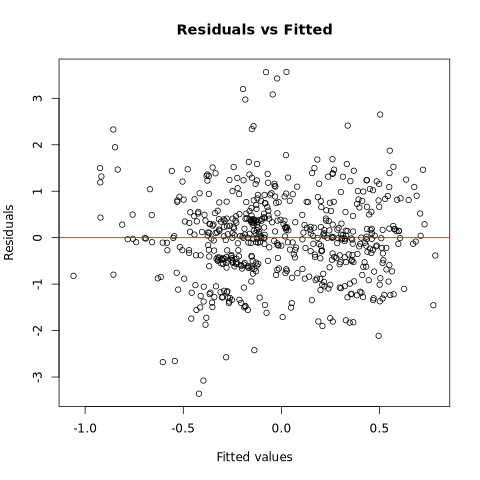

In [19]:
%%R
plot(fitted(grafen_model), residuals(grafen_model),
     xlab = "Fitted values", ylab = "Residuals", 
     main = "Residuals vs Fitted")
abline(h = 0, col = "red")

phylosig(tree, grafen_model$residuals, method = "lambda")

### Plotting

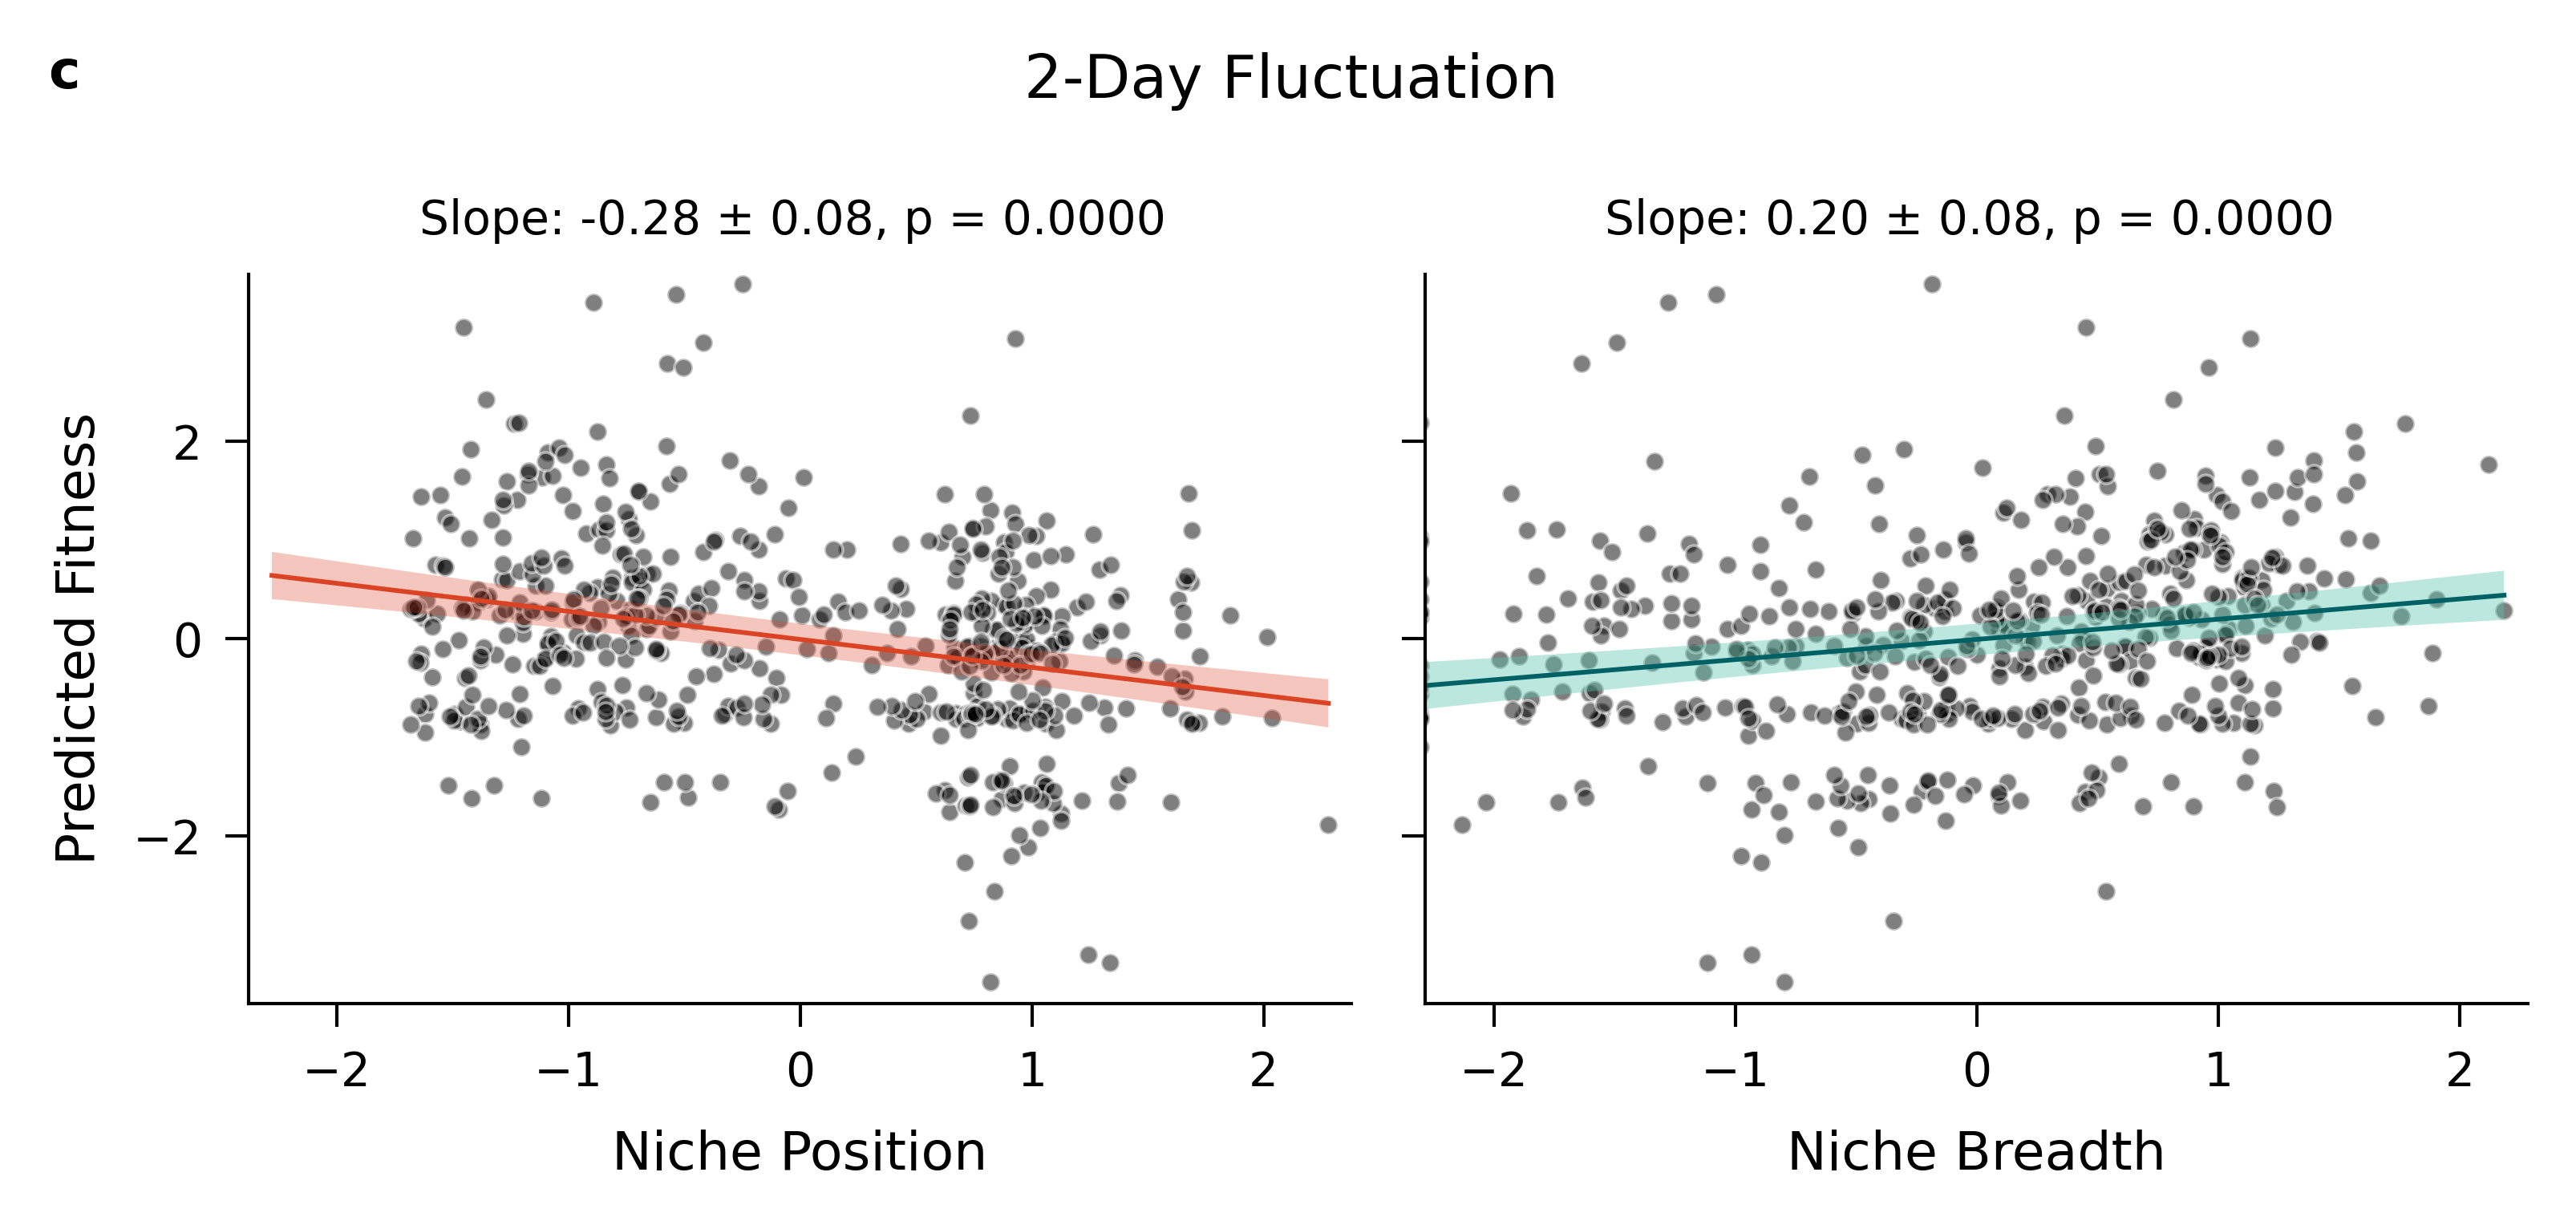

In [20]:
plt.style.use("../nature.mplstyle")

model = "grafen_model"
NP_trait = "NP_fluctuation"
fitness_trait = "TwoDays_fitness"
Condition = "2-Day Fluctuation"
ro.r(f"""
# Extract coefficients
beta = coef({model})
V = vcov({model})

# Build dataframe of trait values holding Bn at mean
simulated_np <- data.frame({NP_trait} = seq(-max(traits${NP_trait}),max(traits${NP_trait}),length.out= 200), Bn= mean(traits$Bn))

# Build dataframe of trait values holding NP at mean
simulated_Bn <- data.frame({NP_trait} = mean(traits${NP_trait}), Bn= seq(min(traits$Bn),max(traits$Bn),length.out= 200))

# Build design matrix for NP predictions
X_np = model.matrix(~ {NP_trait} * Bn, data= simulated_np)
X_np = X_np[,c(1,3,2,4)]

# Build design matrix for NP predictions
X_Bn = model.matrix(~ {NP_trait} * Bn, data= simulated_Bn)
X_Bn = X_Bn[,c(1,3,2,4)]

# Calculate fitted values and confidence intervals for NP
simulated_np$fit <- as.vector(X_np %*% beta) # fitting by matrix multiplication
SE_np <- sqrt(diag(X_np %*% V %*% t(X_np))) # Calculate SE for predicted values
simulated_np$lower <- simulated_np$fit - 1.96 * SE_np
simulated_np$upper <- simulated_np$fit + 1.96 * SE_np

# Calculate fitted values and confidence intervals for Bn
simulated_Bn$fit <- as.vector(X_Bn %*% beta) # fitting by matrix multiplication
SE_Bn <- sqrt(diag(X_Bn %*% V %*% t(X_Bn))) # Calculate SE for predicted values
simulated_Bn$lower <- simulated_Bn$fit - 1.96 * SE_Bn
simulated_Bn$upper <- simulated_Bn$fit + 1.96 * SE_Bn

# Extract coefficients and SE for model
coefficients = coef({model})
errors = summary({model})$tTable[, "Std.Error"]
pvalues = summary({model})$tTable[, "p-value"]

""")

# Pass to Python for plotting
simulated_np = ro.r("simulated_np")
simulated_Bn = ro.r("simulated_Bn")
coefficients = ro.r("coefficients")
errors = ro.r("errors")
pvalues = ro.r("pvalues")
with localconverter(ro.default_converter + pandas2ri.converter):
    simulated_np = ro.conversion.rpy2py(simulated_np)
    simulated_Bn = ro.conversion.rpy2py(simulated_Bn)
    coefficients = ro.conversion.rpy2py(coefficients)
    errors = ro.conversion.rpy2py(errors)
    pvalues = ro.conversion.rpy2py(pvalues)

# Make overall figure
fig,axes = plt.subplots(ncols= 2, nrows= 1, dpi= 600, figsize= (5.35,2.5), sharex= False, sharey= True)

# Niche position plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= NP_trait, y= fitness_trait, ax= axes[0], color= 'k', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_np, x= NP_trait, y='fit', ax= axes[0], color= '#DB4325', linewidth= 0.7)
axes[0].fill_between(x = simulated_np[NP_trait], y1= simulated_np['lower'], y2= simulated_np['upper'],
                     alpha=0.3, color= '#DB4325', ec= None) # Confidence interval
## Add coefficient
axes[0].text(s= f"Slope: {coefficients[2]:.2f} ± {1.96 * errors[2]:.2f}, p = {pvalues[2]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[0].set_xlim((-max(traits[NP_trait])-0.1,max(traits[NP_trait])+0.1))
axes[0].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[0].set_xlabel('Niche Position', labelpad= 5)
axes[0].set_ylabel('Predicted Fitness')


# Niche breadth plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= 'Bn', y= fitness_trait, ax= axes[1], color= 'black', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_Bn, x= 'Bn',y='fit', ax= axes[1], color= '#006164', linewidth= 0.7)
axes[1].fill_between(x = simulated_Bn['Bn'], y1= simulated_Bn['lower'], y2= simulated_Bn['upper'],
                     alpha=0.4, color= '#57C4AD', ec= None) # Confidence interval
## Add coefficient
axes[1].text(s= f"Slope: {coefficients[1]:.2f} ± {1.96 * errors[1]:.2f}, p = {pvalues[1]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[1].set_xlim((-max(traits['Bn'])-0.1,max(traits['Bn']+0.1)))
axes[1].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[1].set_xlabel('Niche Breadth', labelpad= 5)
axes[1].set_ylabel('')


# Global Tidy up
sns.despine()
fig.suptitle(Condition)
fig.text(x= 0.017, y= 0.95, s= 'c', weight= 'bold',fontsize= 8)
plt.tight_layout()

# Save
plt.savefig('../Figures/PGLS/TwoDays_PGLS.svg')
plt.savefig('../Figures/PGLS/TwoDays_PGLS.png')

---
## High Temperature Stable Conditions: Model Relationship Between Niche Breadth, Niche Position, and Fitness

### Fit model

In [21]:
%%R

traits$taxa = rownames(traits)

# Define correlation structures to test
bm_cor <- corBrownian(phy = tree, form= ~taxa)
lambda_cor <- corPagel(1, form= ~taxa, phy = tree, fixed = FALSE)
ou_cor <- corMartins(1, form= ~taxa, phy = tree, fixed = FALSE)
grafen_cor <- corGrafen(1, form= ~taxa, phy = tree, fixed = FALSE)

# Fit all models
## No phylogenetic signal
null_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'ML')

## Brownian motion correlation structure 
brownian_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'ML', correlation= bm_cor)

## Pagel's Lambda correlation structure
lambda_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'ML', correlation= lambda_cor)

## Ornstein-Uhlenbeck correlation structure (CONVERGENCE ISSUE)
#ou_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'ML', correlation = ou_cor)

## Grafen correlation structure
grafen_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'ML', correlation= grafen_cor)

# Create data frame of model names and AICc values
model_names = c('null_model','brownian_model','lambda_model','grafen_model')
                
aicc = c(AICc(null_model),AICc(brownian_model),AICc(lambda_model),AICc(grafen_model))
model_weights = akaike.weights(aicc)$weights
model_fits = data.frame(Model= model_names, AICc= aicc, Akaike_weight= round(model_weights,2))
print(model_fits)

           Model     AICc Akaike_weight
1     null_model 1533.561          0.32
2 brownian_model 1862.498          0.00
3   lambda_model 1534.590          0.19
4   grafen_model 1532.698          0.49


In [22]:
%%R

grafen_model <- gls(highT_fitness ~ Bn + NP_highT + Bn*NP_highT, data= traits, method= 'REML', correlation= grafen_cor)
summary(grafen_model)

Generalized least squares fit by REML
  Model: highT_fitness ~ Bn + NP_highT + Bn * NP_highT 
  Data: traits 
       AIC      BIC    logLik
  1550.062 1576.072 -769.0308

Correlation Structure: corGrafen
 Formula: ~taxa 
 Parameter estimate(s):
        rho 
0.006676641 

Coefficients:
                 Value  Std.Error   t-value p-value
(Intercept)  0.0008764 0.06859508  0.012776  0.9898
Bn           0.0628453 0.04138487  1.518557  0.1294
NP_highT    -0.3558164 0.04039321 -8.808816  0.0000
Bn:NP_highT  0.0395034 0.03925081  1.006436  0.3146

 Correlation: 
            (Intr) Bn     NP_hgT
Bn           0.047              
NP_highT     0.013 -0.004       
Bn:NP_highT -0.059  0.166  0.198

Standardized residuals:
       Min         Q1        Med         Q3        Max 
-4.0009615 -0.5529809 -0.1524515  0.4587053  4.3415216 

Residual standard error: 0.9295679 
Degrees of freedom: 568 total; 564 residual


### Extract Pseudo-R2

In [23]:
%%R

R2_lik(grafen_model)

[1] 0.1203752


### Checking assumptions of homoskedasticity and phylogenetic signal in residuals


Phylogenetic signal lambda : 0.0330083 
logL(lambda) : -761.269 



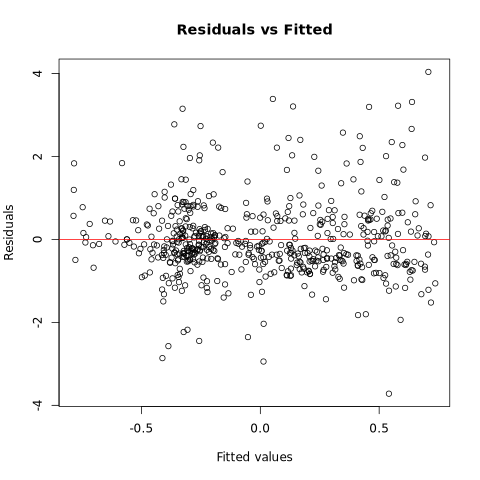

In [24]:
%%R
plot(fitted(grafen_model), residuals(grafen_model),
     xlab = "Fitted values", ylab = "Residuals", 
     main = "Residuals vs Fitted")
abline(h = 0, col = "red")

phylosig(tree, grafen_model$residuals, method = "lambda")

### Plotting

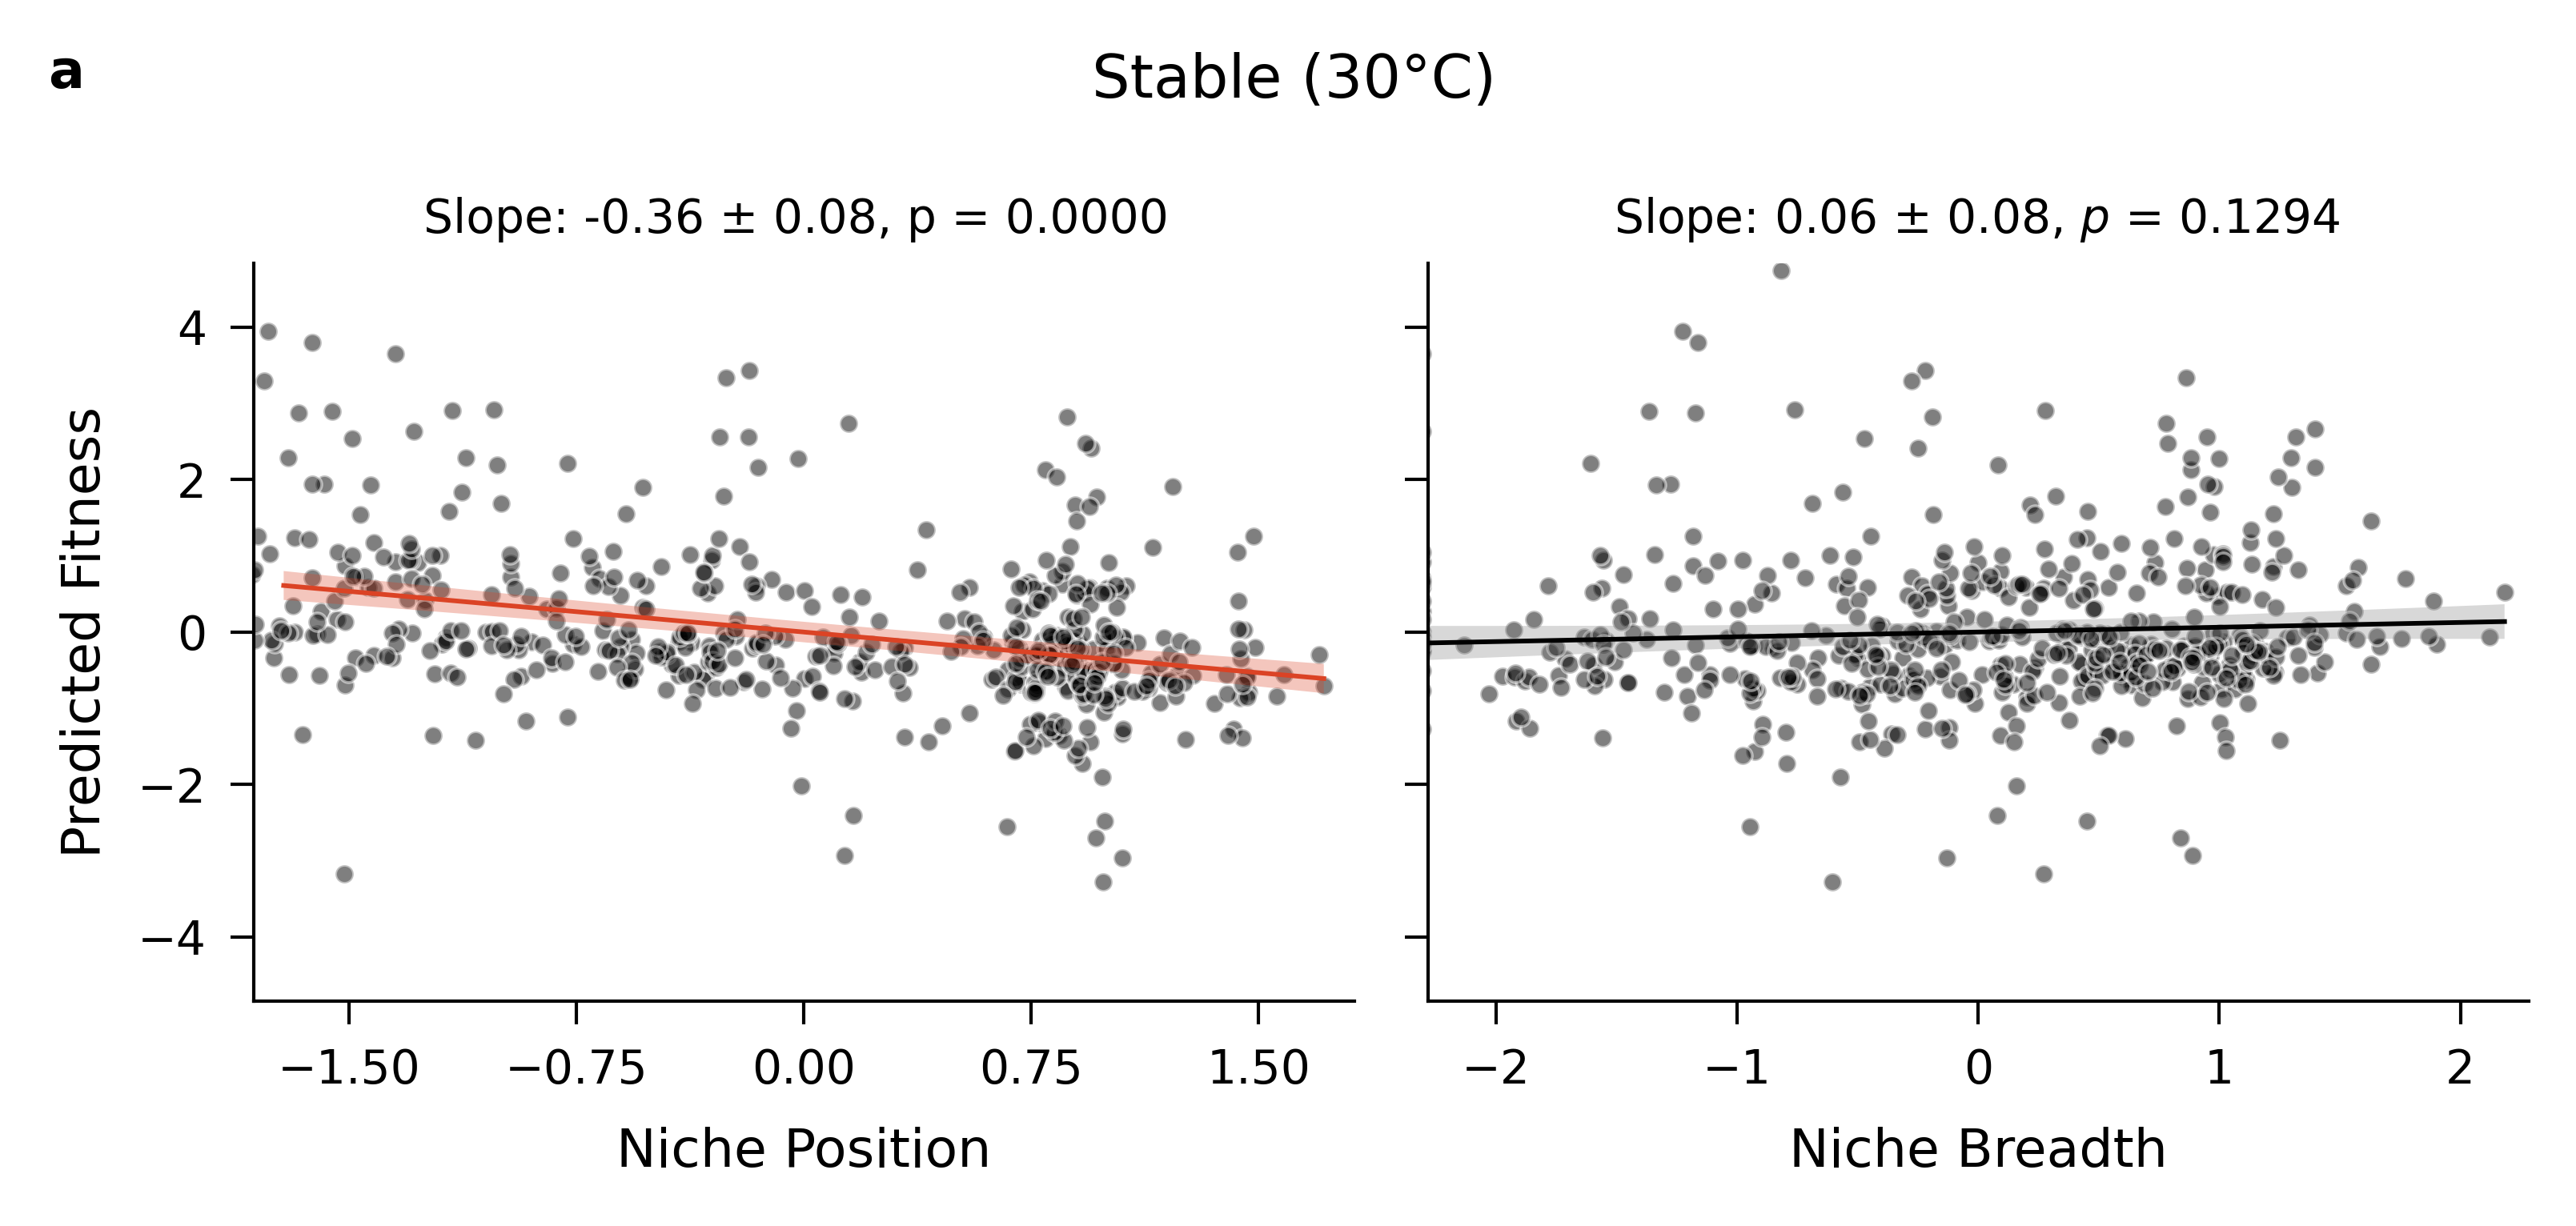

In [25]:
plt.style.use("../nature.mplstyle")

model = "grafen_model"
NP_trait = "NP_highT"
fitness_trait = "highT_fitness"
Condition = "Stable (30°C)"
ro.r(f"""
# Extract coefficients
beta = coef({model})
V = vcov({model})

# Build dataframe of trait values holding Bn at mean
simulated_np <- data.frame({NP_trait} = seq(-max(traits${NP_trait}),max(traits${NP_trait}),length.out= 200), Bn= mean(traits$Bn))

# Build dataframe of trait values holding NP at mean
simulated_Bn <- data.frame({NP_trait} = mean(traits${NP_trait}), Bn= seq(min(traits$Bn),max(traits$Bn),length.out= 200))

# Build design matrix for NP predictions
X_np = model.matrix(~ {NP_trait} * Bn, data= simulated_np)
X_np = X_np[,c(1,3,2,4)]

# Build design matrix for NP predictions
X_Bn = model.matrix(~ {NP_trait} * Bn, data= simulated_Bn)
X_Bn = X_Bn[,c(1,3,2,4)]

# Calculate fitted values and confidence intervals for NP
simulated_np$fit <- as.vector(X_np %*% beta) # fitting by matrix multiplication
SE_np <- sqrt(diag(X_np %*% V %*% t(X_np))) # Calculate SE for predicted values
simulated_np$lower <- simulated_np$fit - 1.96 * SE_np
simulated_np$upper <- simulated_np$fit + 1.96 * SE_np

# Calculate fitted values and confidence intervals for Bn
simulated_Bn$fit <- as.vector(X_Bn %*% beta) # fitting by matrix multiplication
SE_Bn <- sqrt(diag(X_Bn %*% V %*% t(X_Bn))) # Calculate SE for predicted values
simulated_Bn$lower <- simulated_Bn$fit - 1.96 * SE_Bn
simulated_Bn$upper <- simulated_Bn$fit + 1.96 * SE_Bn

# Extract coefficients and SE for model
coefficients = coef({model})
errors = summary({model})$tTable[, "Std.Error"]
pvalues = summary({model})$tTable[, "p-value"]

""")

# Pass to Python for plotting
simulated_np = ro.r("simulated_np")
simulated_Bn = ro.r("simulated_Bn")
coefficients = ro.r("coefficients")
errors = ro.r("errors")
pvalues = ro.r("pvalues")
with localconverter(ro.default_converter + pandas2ri.converter):
    simulated_np = ro.conversion.rpy2py(simulated_np)
    simulated_Bn = ro.conversion.rpy2py(simulated_Bn)
    coefficients = ro.conversion.rpy2py(coefficients)
    errors = ro.conversion.rpy2py(errors)
    pvalues = ro.conversion.rpy2py(pvalues)

# Make overall figure
fig,axes = plt.subplots(ncols= 2, nrows= 1, dpi= 600, figsize= (5.35,2.5), sharex= False, sharey= True)

# Niche position plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= NP_trait, y= fitness_trait, ax= axes[0], color= 'k', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_np, x= NP_trait, y='fit', ax= axes[0], color= '#DB4325', linewidth= 0.7)
axes[0].fill_between(x = simulated_np[NP_trait], y1= simulated_np['lower'], y2= simulated_np['upper'],
                     alpha=0.3, color= '#DB4325', ec= None) # Confidence interval
## Add coefficient
axes[0].text(s= f"Slope: {coefficients[2]:.2f} ± {1.96 * errors[2]:.2f}, p = {pvalues[2]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[0].set_xlim((-max(traits[NP_trait])-0.1,max(traits[NP_trait])+0.1))
axes[0].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[0].set_xlabel('Niche Position', labelpad= 5)
axes[0].set_ylabel('Predicted Fitness')
#axes[0].set_xticks([-2,-1,0,1,2])
axes[0].set_xticks([-1.5,-0.75,0,0.75,1.5])


# Niche breadth plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= 'Bn', y= fitness_trait, ax= axes[1], color= 'black', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_Bn, x= 'Bn',y='fit', ax= axes[1], color= 'black', linewidth= 0.7)
axes[1].fill_between(x = simulated_Bn['Bn'], y1= simulated_Bn['lower'], y2= simulated_Bn['upper'],
                     alpha=0.3, color= 'grey', ec= None) # Confidence interval
## Add coefficient
axes[1].text(s= f"Slope: {coefficients[1]:.2f} ± {1.96 * errors[1]:.2f}, $p$ = {pvalues[1]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[1].set_xlim((-max(traits['Bn'])-0.1,max(traits['Bn']+0.1)))
axes[1].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[1].set_xlabel('Niche Breadth', labelpad= 5)
axes[1].set_ylabel('')
axes[1].locator_params(axis='x', nbins=5)


# Global Tidy up
sns.despine()
fig.suptitle(Condition)
fig.text(x= 0.015, y= 0.95, s= 'a', weight= 'bold',fontsize= 8)
plt.tight_layout()

# Save
plt.savefig('../Figures/PGLS/highT_PGLS.svg')
plt.savefig('../Figures/PGLS/highT_PGLS.png')

---
## Low Temperature Stable Conditions: Model Relationship Between Niche Breadth, Niche Position, and Fitness

### Fit model

In [26]:
%%R

# Define correlation structures to test
bm_cor <- corBrownian(phy = tree, form= ~taxa)
lambda_cor <- corPagel(1, form= ~taxa, phy = tree, fixed = FALSE)
ou_cor <- corMartins(1, form= ~taxa, phy = tree, fixed = FALSE)
grafen_cor <- corGrafen(1, form= ~taxa, phy = tree, fixed = FALSE)

# Fit all models
## No phylogenetic signal
null_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'ML')

## Brownian motion correlation structure 
brownian_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'ML', correlation= bm_cor)

## Pagel's Lambda correlation structure
lambda_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'ML', correlation= lambda_cor)

## Ornstein-Uhlenbeck correlation structure
ou_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'ML', correlation = ou_cor)

## Grafen correlation structure
grafen_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'ML', correlation= grafen_cor)

# Create data frame of model names and AICc values
model_names = c('null_model','brownian_model','lambda_model','ou_model','grafen_model')
                
aicc = c(AICc(null_model),AICc(brownian_model),AICc(lambda_model),AICc(ou_model),AICc(grafen_model))
model_weights = akaike.weights(aicc)$weights
model_fits = data.frame(Model= model_names, AICc= aicc, Akaike_weight= round(model_weights,2))
print(model_fits)

           Model     AICc Akaike_weight
1     null_model 1601.686          0.00
2 brownian_model 1767.241          0.00
3   lambda_model 1567.093          0.89
4       ou_model 1601.984          0.00
5   grafen_model 1571.286          0.11


In [27]:
%%R

lambda_model <- gls(lowT_fitness ~ Bn + NP_lowT + Bn*NP_lowT, data= traits, method= 'REML', correlation= lambda_cor)
summary(lambda_model)

Generalized least squares fit by REML
  Model: lowT_fitness ~ Bn + NP_lowT + Bn * NP_lowT 
  Data: traits 
       AIC      BIC    logLik
  1581.901 1607.911 -784.9503

Correlation Structure: corPagel
 Formula: ~taxa 
 Parameter estimate(s):
   lambda 
0.4173843 

Coefficients:
                 Value  Std.Error  t-value p-value
(Intercept) 0.05922152 0.24095649 0.245777  0.8059
Bn          0.22923984 0.04586089 4.998591  0.0000
NP_lowT     0.00913760 0.04199451 0.217590  0.8278
Bn:NP_lowT  0.02526366 0.03393721 0.744424  0.4569

 Correlation: 
           (Intr) Bn     NP_lwT
Bn          0.081              
NP_lowT    -0.024  0.229       
Bn:NP_lowT  0.073 -0.016  0.120

Standardized residuals:
        Min          Q1         Med          Q3         Max 
-4.22236573 -0.49968339 -0.04041014  0.47100071  4.10703312 

Residual standard error: 1.064346 
Degrees of freedom: 568 total; 564 residual


### Extract Pseudo-R2

In [28]:
%%R

R2_lik(lambda_model)

[1] 0.06966018


### Checking assumptions of homoskedasticity and phylogenetic signal in residuals


Phylogenetic signal lambda : 0.407775 
logL(lambda) : -777.511 



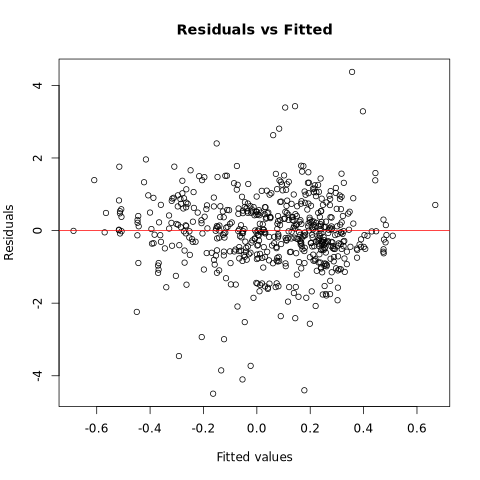

In [29]:
%%R
plot(fitted(lambda_model), residuals(lambda_model),
     xlab = "Fitted values", ylab = "Residuals", 
     main = "Residuals vs Fitted")
abline(h = 0, col = "red")

phylosig(tree, lambda_model$residuals, method = "lambda")

### Plotting

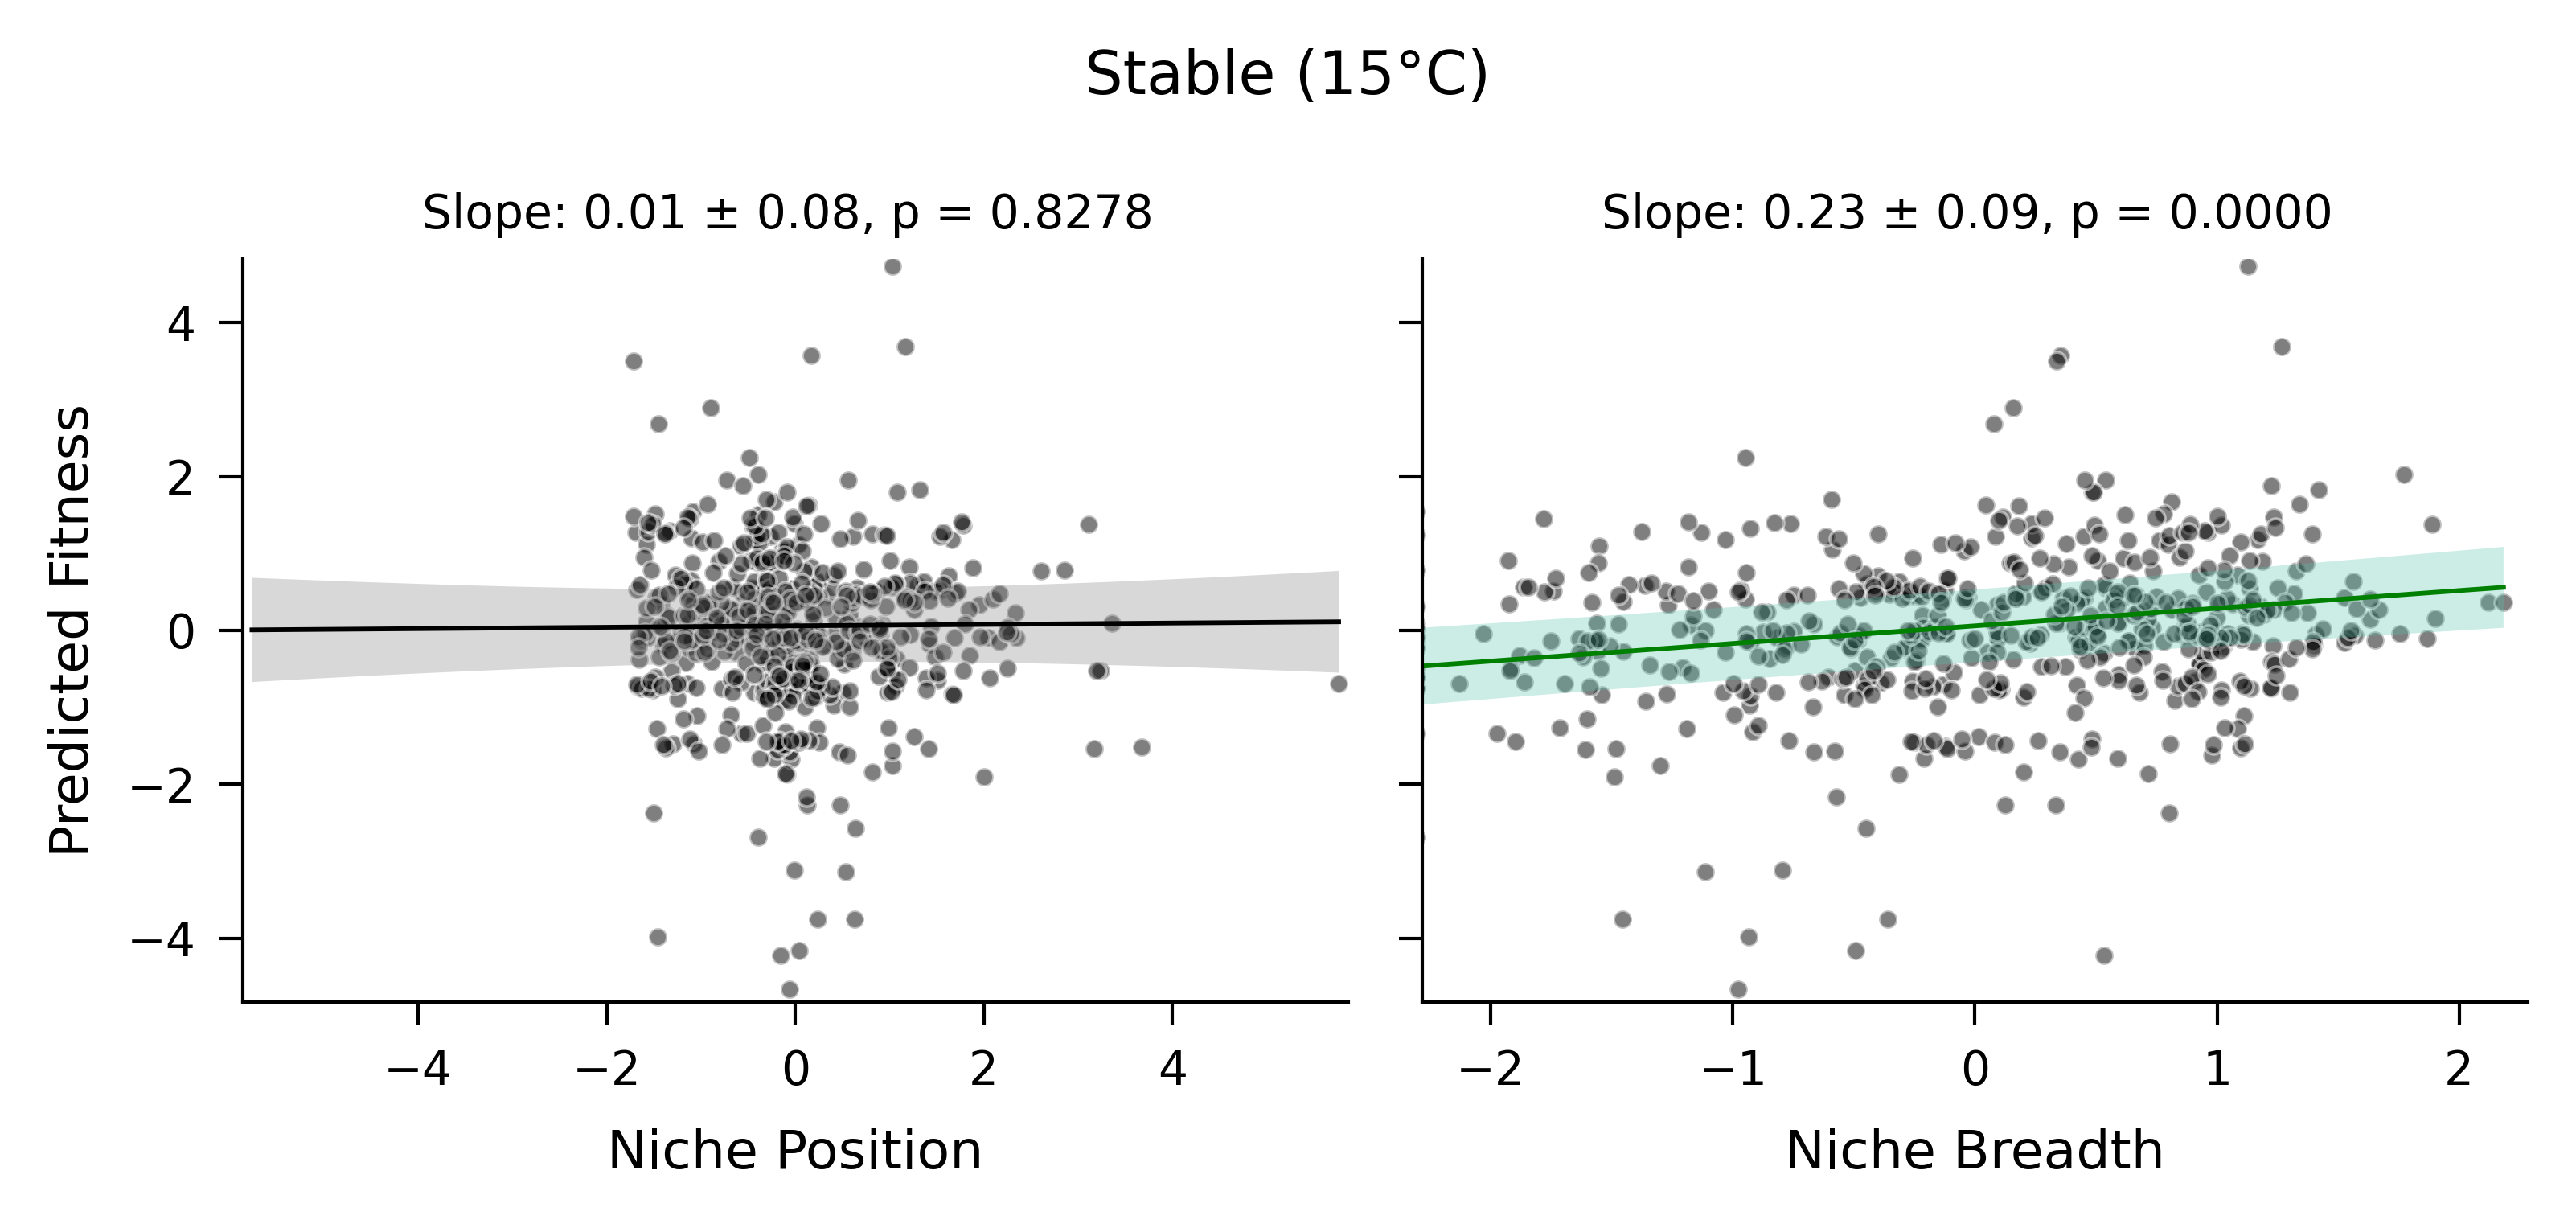

In [30]:
plt.style.use("../nature.mplstyle")

model = "lambda_model"
NP_trait = "NP_lowT"
fitness_trait = "lowT_fitness"
Condition = "Stable (15°C)"
ro.r(f"""
# Extract coefficients
beta = coef({model})
V = vcov({model})

# Build dataframe of trait values holding Bn at mean
simulated_np <- data.frame({NP_trait} = seq(-max(traits${NP_trait}),max(traits${NP_trait}),length.out= 200), Bn= mean(traits$Bn))

# Build dataframe of trait values holding NP at mean
simulated_Bn <- data.frame({NP_trait} = mean(traits${NP_trait}), Bn= seq(min(traits$Bn),max(traits$Bn),length.out= 200))

# Build design matrix for NP predictions
X_np = model.matrix(~ {NP_trait} * Bn, data= simulated_np)
X_np = X_np[,c(1,3,2,4)]

# Build design matrix for NP predictions
X_Bn = model.matrix(~ {NP_trait} * Bn, data= simulated_Bn)
X_Bn = X_Bn[,c(1,3,2,4)]

# Calculate fitted values and confidence intervals for NP
simulated_np$fit <- as.vector(X_np %*% beta) # fitting by matrix multiplication
SE_np <- sqrt(diag(X_np %*% V %*% t(X_np))) # Calculate SE for predicted values
simulated_np$lower <- simulated_np$fit - 1.96 * SE_np
simulated_np$upper <- simulated_np$fit + 1.96 * SE_np

# Calculate fitted values and confidence intervals for Bn
simulated_Bn$fit <- as.vector(X_Bn %*% beta) # fitting by matrix multiplication
SE_Bn <- sqrt(diag(X_Bn %*% V %*% t(X_Bn))) # Calculate SE for predicted values
simulated_Bn$lower <- simulated_Bn$fit - 1.96 * SE_Bn
simulated_Bn$upper <- simulated_Bn$fit + 1.96 * SE_Bn

# Extract coefficients and SE for model
coefficients = coef({model})
errors = summary({model})$tTable[, "Std.Error"]
pvalues = summary({model})$tTable[, "p-value"]

""")

# Pass to Python for plotting
simulated_np = ro.r("simulated_np")
simulated_Bn = ro.r("simulated_Bn")
coefficients = ro.r("coefficients")
errors = ro.r("errors")
pvalues = ro.r("pvalues")
with localconverter(ro.default_converter + pandas2ri.converter):
    simulated_np = ro.conversion.rpy2py(simulated_np)
    simulated_Bn = ro.conversion.rpy2py(simulated_Bn)
    coefficients = ro.conversion.rpy2py(coefficients)
    errors = ro.conversion.rpy2py(errors)
    pvalues = ro.conversion.rpy2py(pvalues)

# Make overall figure
fig,axes = plt.subplots(ncols= 2, nrows= 1, dpi= 600, figsize= (5.35,2.5), sharex= False, sharey= True)

# Niche position plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= NP_trait, y= fitness_trait, ax= axes[0], color= 'k', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_np, x= NP_trait, y='fit', ax= axes[0], color= 'black', linewidth= 0.7)
axes[0].fill_between(x = simulated_np[NP_trait], y1= simulated_np['lower'], y2= simulated_np['upper'],
                     alpha=0.3, color= 'grey', ec= None) # Confidence interval
## Add coefficient
axes[0].text(s= f"Slope: {coefficients[2]:.2f} ± {1.96 * errors[2]:.2f}, p = {pvalues[2]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[0].set_xlim((-max(traits[NP_trait])-0.1,max(traits[NP_trait])+0.1))
axes[0].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[0].set_xlabel('Niche Position', labelpad= 5)
axes[0].set_ylabel('Predicted Fitness')


# Niche breadth plot
## Plot raw data points (in transformed space)
sns.scatterplot(traits, x= 'Bn', y= fitness_trait, ax= axes[1], color= 'black', alpha= 0.5, marker= '.', s= 30)
## Plot fitted line
sns.lineplot(simulated_Bn, x= 'Bn',y='fit', ax= axes[1], color= 'green', linewidth= 0.7)
axes[1].fill_between(x = simulated_Bn['Bn'], y1= simulated_Bn['lower'], y2= simulated_Bn['upper'],
                     alpha=0.3, color= '#57C4AD', ec= None) # Confidence interval
## Add coefficient
axes[1].text(s= f"Slope: {coefficients[1]:.2f} ± {1.96 * errors[1]:.2f}, p = {pvalues[1]:.4f} ", x= 0, y= max(traits[fitness_trait])+0.5,
             ha= 'center')

## Tidy up
axes[1].set_xlim((-max(traits['Bn'])-0.1,max(traits['Bn']+0.1)))
axes[1].set_ylim((-max(traits[fitness_trait])-0.1,max(traits[fitness_trait])+0.1))
axes[1].set_xlabel('Niche Breadth', labelpad= 5)
axes[1].set_ylabel('')


# Global Tidy up
sns.despine()
fig.suptitle(Condition)
plt.tight_layout()

# Save
plt.savefig('../Figures/PGLS/lowT_PGLS.svg')
plt.savefig('../Figures/PGLS/lowT_PGLS.png')